# 01: Weather data: which site, how good, how different

*Phase 2.1 of the extension. The reasoning and the findings are explained in `docs/report.md`, section 2.1.*

The sizing in the performance report and the final report rests on one number, a design DNI of **665 W/m²**, derived from `data/weather_file_nsrdb.csv`. Two things are wrong or missing in that file: its header names **Jodhpur** although the study site is **IIT Bombay**, and it has **no DNI column**. This notebook (1) loads both that file and a PVGIS typical meteorological year for IIT Bombay, (2) checks that they are physically sane, and (3) shows how much the choice of weather data matters.

The result is a comparison, not a new design: the dish model is built in the later notebooks. Figures use the shared style in `en630.plotting` (blue = course file, orange = PVGIS throughout).

In [1]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from en630.plotting import INK, SEQ_BLUE, SERIES, SURFACE, apply_theme, direct_label, save
from en630.weather import (
    COURSE_FILE_SITE, IIT_BOMBAY, _solar_geometry, clean_dni, dni_artefact_mask, dni_from_ghi_dhi, load_nsrdb, read_tmy_csv, to_local, validate,
)

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", message=".*dayofyear.*")  # noise from a pvlib internal
apply_theme()

DATA, FIG = Path("../data"), Path("../docs/figures")
pvgis = validate(read_tmy_csv(DATA / "pvgis_tmy_iitb.csv"), IIT_BOMBAY, timestamp="centre")
course = validate(load_nsrdb(DATA / "weather_file_nsrdb.csv"), COURSE_FILE_SITE, timestamp="start")
pvgis["dni_raw"] = pvgis["dni"]
pvgis["dni"] = clean_dni(pvgis, IIT_BOMBAY, "centre")   # sunrise artefacts zeroed; see section 3
SRC_COURSE, SRC_PVGIS = "Course file (Jodhpur header)", "PVGIS TMY (IIT Bombay)"
MONTHS = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
print(f"PVGIS TMY (IIT Bombay): {pvgis.shape}   course file: {course.shape}   both pass validation")

PVGIS TMY (IIT Bombay): (8760, 8)   course file: (8760, 4)   both pass validation


## 1: What the course file says about itself

In [2]:
header = (DATA / "weather_file_nsrdb.csv").read_text().splitlines()[:2]
print(header[0][:80])
print(header[1][:80])

Source,Location ID,City,State,Country,Latitude,Longitude,Time Zone,Elevation,Loc
NSRDB,20013,Jodhpur,Rajasthan,India,26.35,73.05,5.5,0,5.5,w/m2,w/m2,w/m2,c,m/s


The header says `Jodhpur, Rajasthan, 26.35, 73.05`. The reports say the data is for 19.15 °N, 72.95 °E. The validation rules (no night-time sun, diffuse no larger than global, plausible clear-sky index) pass for **both** sites, because Jodhpur and Mumbai have almost the same longitude. A clean validation therefore says the file is *internally consistent*, not that it is for the right place. The comparison below is what shows the difference.

## 2: Monthly sunshine: course file vs PVGIS at IIT Bombay

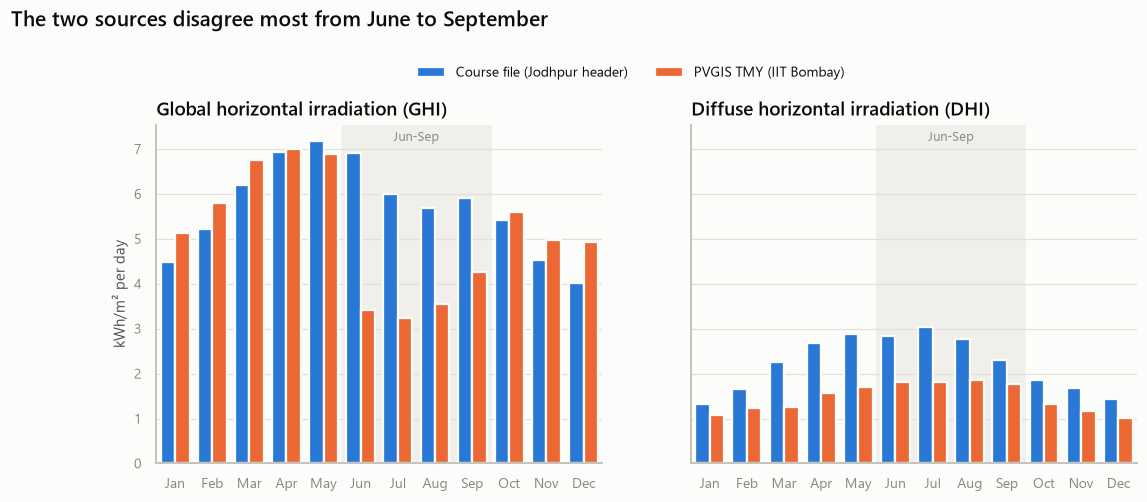

Annual GHI (kWh/m2): {'course file': 2083, 'PVGIS': 1871}
Annual DHI (kWh/m2): {'course file': 814, 'PVGIS': 536}


In [3]:
def daily_kwh(df, col):
    local = to_local(df, IIT_BOMBAY)
    monthly = local.groupby("month")[col].sum() / 1000.0          # kWh/m2 per month
    days = pd.Series({m: pd.Period(f"2001-{m:02d}").days_in_month for m in range(1, 13)})
    return monthly / days                                         # kWh/m2/day


def tidy(col):
    return pd.concat([
        pd.DataFrame({"month": MONTHS, "kwh": daily_kwh(course, col).to_numpy(), "source": SRC_COURSE}),
        pd.DataFrame({"month": MONTHS, "kwh": daily_kwh(pvgis, col).to_numpy(), "source": SRC_PVGIS}),
    ])


fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.0), sharey=True)
for ax, col, title in zip(axes, ("ghi", "dhi"), ("Global horizontal irradiation (GHI)", "Diffuse horizontal irradiation (DHI)")):
    ax.axvspan(4.5, 8.5, color="#f0efec", zorder=0)           # monsoon band, June to September
    sns.barplot(tidy(col), x="month", y="kwh", hue="source", palette=SERIES[:2], width=0.78,
                edgecolor=SURFACE, linewidth=1.5, ax=ax, saturation=1)
    ax.set_title(title)
    ax.set_xlabel("")
    ax.set_ylabel("kWh/m² per day" if col == "ghi" else "")
    ax.grid(axis="x", visible=False)
    ax.text(6.5, 0.98, "Jun-Sep", ha="center", va="top", fontsize=8.5, color=INK["muted"], transform=ax.get_xaxis_transform())
    leg = ax.get_legend()
    if leg: leg.remove()
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=2, bbox_to_anchor=(0.5, 1.04))
fig.suptitle("The two sources disagree most from June to September", x=0.01, y=1.14, ha="left",
             fontsize=14, fontweight="semibold")
save(fig, FIG / "weather_monthly_ghi_dhi.png")
plt.show()
print("Annual GHI (kWh/m2):", {"course file": round(course.ghi.sum() / 1000), "PVGIS": round(pvgis.ghi.sum() / 1000)})
print("Annual DHI (kWh/m2):", {"course file": round(course.dhi.sum() / 1000), "PVGIS": round(pvgis.dhi.sum() / 1000)})

## 3: A data artefact in the PVGIS beam irradiance

PVGIS gives DNI directly, but a first look at it against the height of the sun shows something wrong: a cluster of hours with DNI **above 1100 W/m²** when the sun is only 3 to 4 degrees above the horizon. That is not physical (the extraterrestrial beam is about 1400 W/m² and the air mass near the horizon is huge). It is what you get from computing `(GHI - DHI) / cos(zenith)` with a tiny cosine, and it escaped the closure check in section 8 because the error is multiplied back by the same small cosine. `clean_dni` zeroes the flagged hours, the conservative choice for a dish that cannot work at that sun height; everything below uses the cleaned series unless it says "raw".

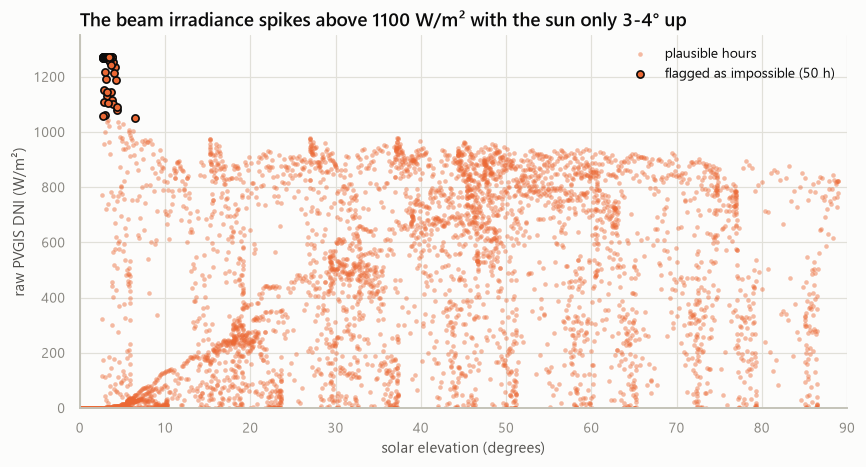

flagged hours: 50, highest elevation among them: 6.4 deg
annual DNI energy: raw 2.113 MWh/m2, cleaned 2.052 MWh/m2 (2.9 % removed)


In [4]:
elev = _solar_geometry(pvgis.index, IIT_BOMBAY, "centre")["elevation"]
bad = dni_artefact_mask(pvgis.assign(dni=pvgis["dni_raw"]), IIT_BOMBAY, "centre")
up = elev > 0

fig, ax = plt.subplots(figsize=(9, 4.4))
ax.scatter(elev[up & ~bad], pvgis["dni_raw"][up & ~bad], s=9, color=SERIES[1], alpha=0.45, linewidths=0, label="plausible hours")
ax.scatter(elev[bad], pvgis["dni_raw"][bad], s=22, color=SERIES[1], edgecolor=INK["primary"], linewidth=1.1, label=f"flagged as impossible ({int(bad.sum())} h)", zorder=4)
ax.set_xlabel("solar elevation (degrees)")
ax.set_ylabel("raw PVGIS DNI (W/m²)")
ax.set_xlim(0, 90); ax.set_ylim(0, 1350)
ax.legend(loc="upper right")
ax.set_title("The beam irradiance spikes above 1100 W/m² with the sun only 3-4° up")
save(fig, FIG / "weather_dni_artefact.png")
plt.show()
n_raw, n_clean = pvgis["dni_raw"].sum() / 1e6, pvgis["dni"].sum() / 1e6
print(f"flagged hours: {int(bad.sum())}, highest elevation among them: {elev[bad].max():.1f} deg")
print(f"annual DNI energy: raw {n_raw:.3f} MWh/m2, cleaned {n_clean:.3f} MWh/m2 ({(1 - n_clean / n_raw) * 100:.1f} % removed)")

## 4: Direct normal irradiance by hour and month (PVGIS, local time, cleaned)

DNI is what a concentrating dish uses. The monsoon months show up as a pale band.

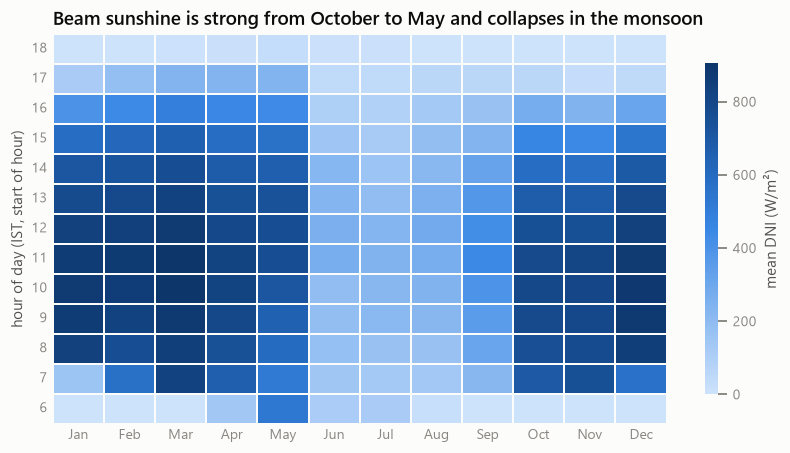

DNI energy per month (kWh/m2): {1: 218.0, 2: 210.0, 3: 255.0, 4: 225.0, 5: 224.0, 6: 63.0, 7: 60.0, 8: 68.0, 9: 99.0, 10: 205.0, 11: 199.0, 12: 226.0}


In [5]:
local = to_local(pvgis, IIT_BOMBAY)
heat = local.pivot_table(index="hour", columns="month", values="dni", aggfunc="mean").loc[6:18]
heat.columns = MONTHS
fig, ax = plt.subplots(figsize=(9, 4.6))
sns.heatmap(heat, cmap=SEQ_BLUE, linewidths=1.2, linecolor=SURFACE, square=False, ax=ax,
            cbar_kws={"label": "mean DNI (W/m²)", "shrink": 0.85, "aspect": 25}, vmin=0)
ax.invert_yaxis()
ax.set_xlabel("")
ax.set_ylabel("hour of day (IST, start of hour)")
ax.grid(False)
ax.tick_params(length=0, labelrotation=0)
ax.set_title("Beam sunshine is strong from October to May and collapses in the monsoon")
save(fig, FIG / "weather_dni_heatmap.png")
plt.show()
monthly_dni = (local.groupby("month")["dni"].sum() / 1000).round(0)
print("DNI energy per month (kWh/m2):", monthly_dni.to_dict())

## 5: The design-DNI question

The performance report counts only hours with DNI above 200 W/m² and quotes a design DNI of 665 W/m² and **1.6488 MWh/m²** a year; the final report uses 665 W/m². The course file has no DNI, so for it DNI is derived from the closure relation `(GHI - DHI) / cos(zenith)`, a crude baseline (see `dni_from_ghi_dhi`). PVGIS provides DNI directly.

In [6]:
dni_course = dni_from_ghi_dhi(course, COURSE_FILE_SITE, timestamp="start")


def stats(dni, label):
    hi = dni[dni > 200]
    return {
        "source": label,
        "hours with DNI > 200": len(hi),
        "mean DNI of those hours (W/m²)": round(hi.mean()),
        "annual energy above 200 (MWh/m²)": round(hi.sum() / 1e6, 3),
        "annual DNI energy, all hours (MWh/m²)": round(dni.sum() / 1e6, 3),
    }


table = pd.DataFrame([
    stats(dni_course, "course file, DNI derived from GHI and DHI"),
    stats(pvgis["dni_raw"], "PVGIS TMY, IIT Bombay (raw)"),
    stats(pvgis["dni"], "PVGIS TMY, IIT Bombay (cleaned)"),
]).set_index("source")
reported = pd.DataFrame(
    {
        "hours with DNI > 200": [np.nan],
        "mean DNI of those hours (W/m²)": [665],
        "annual energy above 200 (MWh/m²)": [1.6488],
        "annual DNI energy, all hours (MWh/m²)": [np.nan],
    },
    index=["as reported in the performance and final reports"],
)
table = pd.concat([table, reported])
table

,hours with DNI > 200,mean DNI of those hours (W/m²),annual energy above 200 (MWh/m²),"annual DNI energy, all hours (MWh/m²)"
"course file, DNI derived from GHI and DHI",3246.0,560,1.8160,1.873
"PVGIS TMY, IIT Bombay (raw)",3169.0,643,2.0370,2.113
"PVGIS TMY, IIT Bombay (cleaned)",3119.0,634,1.9760,2.052
as reported in the performance and final reports,NaN,665,1.6488,NaN


Reading the table: the reports' 665 W/m² is **above** the mean DNI of both series (560 for the course file, 643 raw and 634 cleaned PVGIS, for hours above 200), while the performance report's 1.6488 MWh/m² is **below** the annual energy above 200 W/m² of every series (1.816, 2.037 raw, 1.976 cleaned). The two reported figures do not come from one consistent calculation on either series. The PVGIS figure is a *model* estimate (ERA5-based), not a ground measurement, and the closure-derived DNI for the course file is a crude baseline. So the table shows the sensitivity to the data source, not which number is right. Measured DNI at the site, or an independent satellite product, would be needed to say.

## 6: How many hours are usable? DNI duration curve

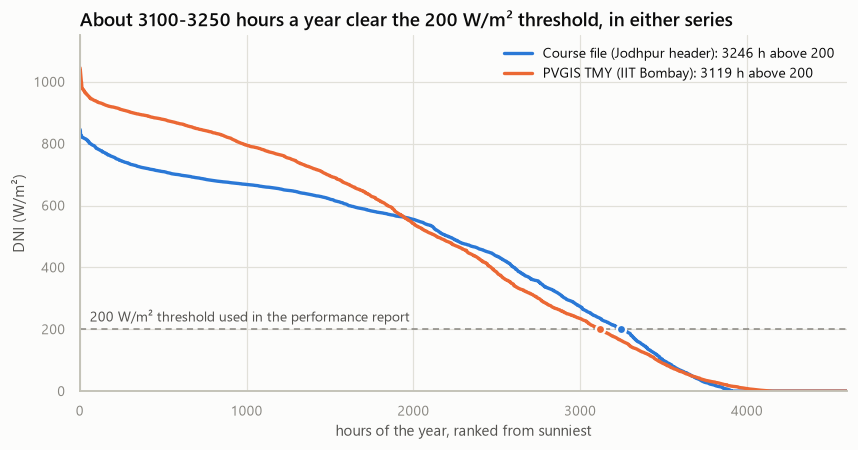

In [7]:
fig, ax = plt.subplots(figsize=(9, 4.2))
curves = {SRC_COURSE: dni_course.sort_values(ascending=False).to_numpy(),
          SRC_PVGIS: pvgis["dni"].sort_values(ascending=False).to_numpy()}
for (name, y), color in zip(curves.items(), SERIES):
    n_above = int((y > 200).sum())
    ax.plot(np.arange(1, len(y) + 1), y, color=color, linewidth=2.2, label=f"{name}: {n_above} h above 200")
    ax.plot([n_above], [200], marker="o", markersize=6, color=color, markeredgecolor=SURFACE, markeredgewidth=1.5, zorder=5)
ax.axhline(200, color=INK["muted"], linewidth=1, linestyle=(0, (4, 3)))
ax.text(60, 225, "200 W/m² threshold used in the performance report", fontsize=9, color=INK["secondary"])
ax.set_xlim(0, 4600)
ax.set_ylim(0, 1150)
ax.set_xlabel("hours of the year, ranked from sunniest")
ax.set_ylabel("DNI (W/m²)")
ax.legend(loc="upper right")
ax.set_title("About 3100-3250 hours a year clear the 200 W/m² threshold, in either series")
save(fig, FIG / "weather_dni_duration.png")
plt.show()

## 7: Monthly DNI: course file vs PVGIS

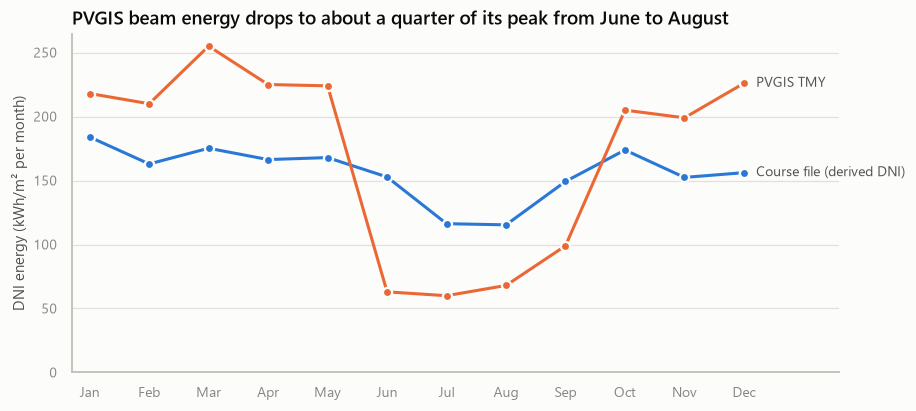

In [8]:
m_course = to_local(pd.DataFrame({"dni": dni_course}), COURSE_FILE_SITE).groupby("month")["dni"].sum() / 1000
m_pvgis = monthly_dni
fig, ax = plt.subplots(figsize=(9, 4.0))
x = np.arange(12)
for y, color, name in ((m_course.to_numpy(), SERIES[0], "Course file (derived DNI)"),
                       (m_pvgis.to_numpy(), SERIES[1], "PVGIS TMY")):
    ax.plot(x, y, color=color, marker="o", markersize=6, markeredgecolor=SURFACE, markeredgewidth=1.5)
    direct_label(ax, x[-1], y[-1], name, color)
ax.set_xticks(x, MONTHS)
ax.set_xlim(-0.3, 12.6)
ax.set_ylim(0, None)
ax.set_ylabel("DNI energy (kWh/m² per month)")
ax.grid(axis="x", visible=False)
ax.set_title("PVGIS beam energy drops to about a quarter of its peak from June to August")
save(fig, FIG / "weather_monthly_dni.png")
plt.show()

## 8: Consistency of the PVGIS series (diagnostic)

If GHI, DHI and DNI are consistent, `GHI about DHI + DNI x cos(zenith)`. The plot compares the two sides hour by hour; large scatter would mean DNI cannot be trusted as a beam value. Note the limit of this test: it passes for the artefact hours of section 3 too.

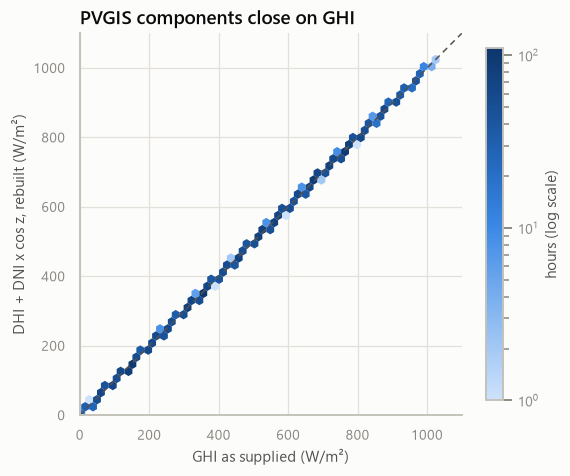

daytime hours (sun > 10°)          3816.0
mean residual (W/m²)                 -0.2
mean |residual| (W/m²)                0.4
hours with |residual| > 50 W/m²       0.0
dtype: float64

In [9]:
sun = _solar_geometry(pvgis.index, IIT_BOMBAY, "centre")
cosz = np.sin(np.radians(sun["elevation"])).clip(lower=0)
rebuilt = pvgis["dhi"] + pvgis["dni"] * cosz
resid = pvgis["ghi"] - rebuilt
day = sun["elevation"] > 10

fig, ax = plt.subplots(figsize=(5.6, 5.2))
hb = ax.hexbin(pvgis["ghi"][day], rebuilt[day], gridsize=45, cmap=SEQ_BLUE, bins="log", mincnt=1, linewidths=0)
lim = 1100
ax.plot([0, lim], [0, lim], color=INK["secondary"], linewidth=1, linestyle=(0, (4, 3)))
ax.set_xlim(0, lim); ax.set_ylim(0, lim); ax.set_aspect("equal")
ax.set_xlabel("GHI as supplied (W/m²)"); ax.set_ylabel("DHI + DNI x cos z, rebuilt (W/m²)")
ax.set_title("PVGIS components close on GHI")
fig.colorbar(hb, ax=ax, label="hours (log scale)", shrink=0.8)
save(fig, FIG / "weather_pvgis_closure.png")
plt.show()
pd.Series({
    "daytime hours (sun > 10°)": int(day.sum()),
    "mean residual (W/m²)": round(resid[day].mean(), 1),
    "mean |residual| (W/m²)": round(resid[day].abs().mean(), 1),
    "hours with |residual| > 50 W/m²": int((resid[day].abs() > 50).sum()),
})

## What this notebook establishes, and what it does not

* **Established:** both datasets are internally valid; PVGIS supplies DNI and is for the right site; the two sources differ materially in diffuse and beam energy, so the data source is a first-order assumption of the sizing; and PVGIS DNI contains 50 impossible sunrise hours, now flagged and zeroed (about 2.9 % of annual DNI energy).
* **Not established:** the true site DNI (both series are modelled), which source the original 665 W/m² came from, and whether the ERA5-based PVGIS DNI is biased during the monsoon. These are listed as next steps in `FUTURE_SCOPE.md`.
* **Next:** notebook 02 reproduces the final report numbers from their stated inputs before anything is changed.